In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import yaml
import sys
from pathlib import Path
import mlflow
import os
import joblib
import logging
import gc

# Loading & Splits

## Loading

### Loading config and path

In [2]:
PROJECT_ROOT = Path("..").resolve()
sys.path.append(str(PROJECT_ROOT))

CONFIG_PATH = PROJECT_ROOT / "config" / "config.yaml"
with open(CONFIG_PATH, "r") as f:
    config = yaml.safe_load(f)

FEATURES_PATH = PROJECT_ROOT / config["data"]["features_path"]

# Splits
V5_TRAIN_START = config["splits"]["drift_detection_year"]
V5_TRAIN_END = config["splits"]["v2_train_end"]
V5_VAL_START = config["splits"]["v2_val_start"]
V5_VAL_END = config["splits"]["v2_val_end"]
V5_TEST_START = config["splits"]["v2_test_start"]
V5_TEST_END = config["splits"]["v2_test_end"]

RANDOM_STATE = config["random_state"]
FEATURE_COLS = config["feature_cols"]

print("Config loaded")
print(f"Features Path : {FEATURES_PATH}")

Config loaded
Features Path : C:\Users\HP\Documents\Fraud_Detection_System\data\features\features.parquet


### Loading logger

In [3]:
# Loading logger
LOG_DIR = PROJECT_ROOT / "logs"
LOG_DIR.mkdir(parents=True, exist_ok=True)

LOG_FILE = LOG_DIR / "v5_model_notebook.log"

logging.basicConfig(
    level= logging.INFO,
    format= "%(asctime)s | %(levelname)s | %(message)s",
    datefmt= "%d-%m-%Y %H:%M:%S",
    handlers= [
        logging.FileHandler(LOG_FILE),
        logging.StreamHandler()
    ]
)
logger = logging.getLogger(__name__)

logger.info("Jupyter Notebook v5_post_chip_smote.ipynb")

10-10-2026 14:51:32 | INFO | Jupyter Notebook v5_post_chip_smote.ipynb


### Loading Features

In [4]:
import duckdb

print("Loading Features using DuckDB ...")

con = duckdb.connect()
con.execute(f"PRAGMA threads={config['duckdb']['threads']}")
con.execute(f"PRAGMA memory_limit='{config['duckdb']['memory_limit']}'")

DF_COLS = FEATURE_COLS + ["timestamp", "is_fraud"]
cols_sql = ", ".join(DF_COLS)

df = con.execute(f"""
    SELECT {cols_sql}
    FROM read_parquet('{FEATURES_PATH}')
    WHERE YEAR(timestamp) >= {V5_TRAIN_START}
        AND YEAR(timestamp) <= {V5_TEST_END}
    """).df()

con.close()

print(f"Shape : {df.shape}")
print(f"Rows : {len(df):,}")
print(f"Columnns : {df.shape[1]}")
print(f"Timestamp range : {df['timestamp'].min()} to {df['timestamp'].max()}")
print(f"Fraud Rate : {df['is_fraud'].mean():.6f}")
print(f"Nulls : {df.isna().sum().sum()}")
print(f"Columns in df : \n{df.columns.tolist()}")

Loading Features using DuckDB ...


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Shape : (8915646, 40)
Rows : 8,915,646
Columnns : 40
Timestamp range : 2015-01-01 00:01:00 to 2020-02-28 23:58:00
Fraud Rate : 0.001312
Nulls : 0
Columns in df : 
['amount', 'is_refund', 'is_high_value', 'is_online', 'error_bad_cvv', 'error_bad_expiration', 'error_bad_card', 'error_bad_pin', 'day_of_week', 'is_weekend', 'is_night', 'hour_sin', 'hour_cos', 'minutes_since_last_txn', 'mcc_frequency', 'card_txn_count_60min', 'card_txn_count_1440min', 'card_txn_count_30d', 'card_txn_count_365d', 'card_spend_mean_30d', 'card_spend_std_30d', 'user_txn_count_60min', 'user_txn_count_1440min', 'user_txn_count_30d', 'user_txn_count_365d', 'user_spend_mean_30d', 'user_spend_std_30d', 'card_amount_zscore_30d', 'user_amount_zscore_30d', 'card_amount_zscore_365d', 'user_is_new_city', 'user_amount_zscore_365d', 'card_is_new_state', 'user_is_new_state', 'card_is_new_city', 'card_is_new_merchant', 'user_is_new_merchant', 'distinct_cards_used_1440min', 'timestamp', 'is_fraud']


## Feature Groups

In [5]:
velocity_card_cols = ['card_txn_count_60min', 'card_txn_count_1440min', 
                      'card_txn_count_30d', 'card_txn_count_365d']

spend_card_cols = ['card_spend_mean_30d', 'card_spend_std_30d']

velocity_user_cols = ['user_txn_count_60min', 'user_txn_count_1440min', 
                     'user_txn_count_30d', 'user_txn_count_365d']

spend_user_cols = ['user_spend_mean_30d', 'user_spend_std_30d']

zscore_features = ["card_amount_zscore_30d", "user_amount_zscore_30d", 
                   "card_amount_zscore_365d", "user_amount_zscore_365d"]

geo_features = ["card_is_new_state", "user_is_new_state", "card_is_new_city", 
            "user_is_new_city"]

In [6]:
feature_groups = {
    "Raw" : ["amount", "is_refund", "is_high_value", "is_online", "error_bad_cvv", 
             "error_bad_expiration", "error_bad_card", "error_bad_pin"],
    
    "Temporal" : ["day_of_week", "is_weekend", "is_night", "hour_sin", 
                  "hour_cos", "minutes_since_last_txn"],

    "MCC Encoding" : ["mcc_frequency"],

    "Card Velocity" : velocity_card_cols,
    "Card Spend" : spend_card_cols,

    "User Velocity" : velocity_user_cols,
    "User Spend" : spend_user_cols,

    "Z-Scores" : zscore_features,

    "Merchant Familiarity" : ["card_is_new_merchant", "user_is_new_merchant"],

    "Cross-Card" : ["distinct_cards_used_1440min"],

    "Geographical" : geo_features
}

In [7]:
missing = [c for c in FEATURE_COLS if c not in df.columns]
if missing:
    print(f"Missing Columns : {missing}")

print(f"\nFeature Groups :")
for group, col in feature_groups.items():
    print(f"{group : <25}{len(col)} features")

print(f"\nTotal Features : {len(FEATURE_COLS)}")
print("Target : is_fraud")

del (
    velocity_card_cols, spend_card_cols, velocity_user_cols, spend_user_cols, zscore_features, 
    geo_features, feature_groups, missing
)
gc.collect()


Feature Groups :
Raw                      8 features
Temporal                 6 features
MCC Encoding             1 features
Card Velocity            4 features
Card Spend               2 features
User Velocity            4 features
User Spend               2 features
Z-Scores                 4 features
Merchant Familiarity     2 features
Cross-Card               1 features
Geographical             4 features

Total Features : 38
Target : is_fraud


100

## V5 Train / Val / Test Split

In [8]:
year = df["timestamp"].dt.year

v5_train = df[(year >= V5_TRAIN_START) & (year <= V5_TRAIN_END)]
v5_val = df[(year >= V5_VAL_START) & (year <= V5_VAL_END)]
v5_test = df[(year >= V5_TEST_START) & (year <= V5_TEST_END)]

del df
gc.collect()

x_train = v5_train[FEATURE_COLS].astype("float32")
y_train = v5_train["is_fraud"]

x_val = v5_val[FEATURE_COLS].astype("float32")
y_val = v5_val["is_fraud"]
fraud_amount_val = v5_val.loc[y_val == 1, "amount"].values

x_test = v5_test[FEATURE_COLS].astype("float32")
y_test = v5_test["is_fraud"]
test_fraud_amount = v5_test.loc[y_test == 1, "amount"].values

del v5_train, v5_val, v5_test
gc.collect()

print("V5 Splits : \n")
print(f"{'Splits':<6}{'Rows':>10}{'Fraud':>8}{'Non Fraud':>12}{'Fraud Rate':>12}")

for name, x, y in [
    ("Train", x_train, y_train),
    ("Val", x_val, y_val),
    ("Test", x_test, y_test)
]:
    fraud_count = y.sum()
    non_fraud_count = len(y) - fraud_count
    fraud_rate = y.mean()
    print(f"{name:<6}{len(y):>10,}{fraud_count:>8,}{non_fraud_count:>12,}{fraud_rate:>10.5f}")

V5 Splits : 

Splits      Rows   Fraud   Non Fraud  Fraud Rate
Train  5,133,618   7,115   5,126,503   0.00139
Val    1,721,605   2,491   1,719,114   0.00145
Test   2,060,423   2,087   2,058,336   0.00101


## Borderline SMOTE

In [9]:
from imblearn.over_sampling import BorderlineSMOTE

print("Before Borderline SMOTE :")
print(f"Frauds : {y_train.sum():,}")
print(f"Fraud Rate : {y_train.mean():.6f}")

SAMPLING_STRATEGY = config["model"]["smote"]["sampling_strategy"]
KIND = config["model"]["smote"]["kind"]

smote = BorderlineSMOTE(
    sampling_strategy=SAMPLING_STRATEGY,
    random_state=RANDOM_STATE,
    kind=KIND,
)

x_train_smote, y_train_smote = smote.fit_resample(x_train, y_train)

x_train_smote = pd.DataFrame(
    x_train_smote,
    columns=FEATURE_COLS
).astype("float32")

y_train_smote = pd.Series(y_train_smote, name="is_fraud")

print("\nAfter applying Borderline SMOTE")
print(f"Frauds : {y_train_smote.sum():,}")
print(f"Fraud Rate : {y_train_smote.mean():.6f}")

print(f"\nSynthetic Frauds generated : {y_train_smote.sum() - y_train.sum():,}")
print(f"Total training rows before SMOTE : {len(x_train):,}")
print(f"Total training rows after SMOTE : {len(x_train_smote):,}")

del x_train, y_train
gc.collect()

Before Borderline SMOTE :
Frauds : 7,115
Fraud Rate : 0.001386

After applying Borderline SMOTE
Frauds : 51,265
Fraud Rate : 0.009901

Synthetic Frauds generated : 44,150
Total training rows before SMOTE : 5,133,618
Total training rows after SMOTE : 5,177,768


0

## V5 scale_pos_weight after Borderline SMOTE

In [10]:
# Calculating scale_pos_weights from post-SMOTE training data
v5_scale_pos_weight = float((y_train_smote == 0).sum()) / float(y_train_smote.sum())
v5_scale_pos_weight = round(v5_scale_pos_weight, 4)

print(f"Training period : {V5_TRAIN_START}-{V5_TRAIN_END}")

print("\nAfter SMOTE :")
print(f"Fraud in train : {y_train_smote.sum():,}")
print(f"Non-fraud in train : {(y_train_smote == 0).sum():,}")
print(f"V5 scale_pos_weight (post-SMOTE) : {v5_scale_pos_weight}")

v4_scale_pos_weight = config["model"]["lgbm"]["baseline"]["v4_scale_pos_weight"]
print(f"\nV5 scale_pos_weight (pre-SMOTE) : {v4_scale_pos_weight}")
print(f"Difference : {v5_scale_pos_weight - v4_scale_pos_weight:+.5f}")

# Saving scale_pos_weight to config
config["model"]["lgbm"]["baseline"]["v5_scale_pos_weight"] = v5_scale_pos_weight
with open(CONFIG_PATH, "w") as f:
    yaml.safe_dump(config, f, sort_keys=False)
print("\nSaved V5 scale_pos_weight to config.yaml")

# Comparison with V1 scale_pos_weight
v1_scale_pos_weight = config["model"]["lgbm"]["baseline"]["scale_pos_weight"]
print(f"\nV1 scale_pos_weight : {v1_scale_pos_weight}")
print(f"Difference : {v5_scale_pos_weight - v1_scale_pos_weight:+.5f}")

Training period : 2015-2017

After SMOTE :
Fraud in train : 51,265
Non-fraud in train : 5,126,503
V5 scale_pos_weight (post-SMOTE) : 100.0001

V5 scale_pos_weight (pre-SMOTE) : 708.8339
Difference : -608.83380

Saved V5 scale_pos_weight to config.yaml

V1 scale_pos_weight : 649.4353
Difference : -549.43520


# Models

## LightGBM

### V5 LightGBM with V2 tuned hyperparameters

In [11]:
# Val for Early Stopping
VAL_TUNE_SIZE = config["model"]["lgbm"]["val_tune_size"]

fraud_val_idx = x_val[y_val == 1].index
non_fraud_val_idx = x_val[y_val == 0].index

# Oversampling frauds
tune_val_fraud_count = min(len(fraud_val_idx), 1000)
tune_val_non_fraud_count = VAL_TUNE_SIZE - tune_val_fraud_count

tune_val_idx = np.concatenate([
    np.random.RandomState(RANDOM_STATE).choice(fraud_val_idx, tune_val_fraud_count, replace=False),
    np.random.RandomState(RANDOM_STATE).choice(non_fraud_val_idx, tune_val_non_fraud_count, replace=False)
])

x_val_tune = x_val.loc[tune_val_idx]
y_val_tune = y_val.loc[tune_val_idx]


print(f"Full V5 Val Size : {len(x_val):,}")
print(f"Early Stopping V5 Val Size : {len(x_val_tune):,}")

print(f"\nFull Val Fraud Count : {y_val.sum():,}")
print(f"Tune Val Fraud Count : {tune_val_fraud_count:,}")
print(f"Tune Val Non-Fraud Count : {tune_val_non_fraud_count:,}")

print(f"\nFull V5 Val Fraud Rate : {y_val.mean():.6f}")
print(f"Tune V5 Val Fraud Rate : {y_val_tune.mean():.6f}")

Full V5 Val Size : 1,721,605
Early Stopping V5 Val Size : 200,000

Full Val Fraud Count : 2,491
Tune Val Fraud Count : 1,000
Tune Val Non-Fraud Count : 199,000

Full V5 Val Fraud Rate : 0.001447
Tune V5 Val Fraud Rate : 0.005000


In [12]:
import lightgbm as lgb

SCALE_POS_WEIGHT = v5_scale_pos_weight

v2_tuned_parameters = {
    "objective" : config["model"]["lgbm"]["baseline"]["objective"],
    "scale_pos_weight" : SCALE_POS_WEIGHT,
    "random_state" : RANDOM_STATE,
    "verbosity" : -1,
    "n_jobs" : -1,
    **config["model"]["lgbm"]["v2_tuned"]
}

print("Training V5 LightGBM with V2 tuned hyperparameters ...")
print(f"Parameters : \n{v2_tuned_parameters}\n")

lgbm_v5_base = lgb.LGBMClassifier(**v2_tuned_parameters)
lgbm_v5_base.fit(
    x_train_smote, y_train_smote,
        callbacks=[
            lgb.log_evaluation(period=-1)
        ]
)

print("\nV5 LightGBM with V2 tuned hyperparameters Trained")
print(f"Trees used : {v2_tuned_parameters['n_estimators']}")

Training V5 LightGBM with V2 tuned hyperparameters ...
Parameters : 
{'objective': 'binary', 'scale_pos_weight': 100.0001, 'random_state': 42, 'verbosity': -1, 'n_jobs': -1, 'learning_rate': 0.011269656488047454, 'max_depth': 12, 'n_estimators': 4600, 'num_leaves': 72, 'feature_fraction': 0.5028180600816718, 'min_child_samples': 119, 'reg_alpha': 0, 'reg_lambda': 1e-06}


V5 LightGBM with V2 tuned hyperparameters Trained
Trees used : 4600


### V5 Base Model Evaluation

In [13]:
from sklearn.metrics import (
    average_precision_score, roc_auc_score, f1_score,
    recall_score, precision_score, roc_curve
)

from src.models.model_utils import evaluate_model

V1_THRESHOLD = config["model"]["threshold"]
    
v5_base_val_prob, v5_base_val_metrics = evaluate_model(
    lgbm_v5_base, x_val, y_val, threshold=V1_THRESHOLD, split_name="V5 Base Val"
)

10-10-2026 15:41:15 | INFO | V5 Base Val Evaluation (threshold = 0.6):
10-10-2026 15:41:15 | INFO | pr_auc             : 0.10596
10-10-2026 15:41:15 | INFO | roc_auc            : 0.91449
10-10-2026 15:41:15 | INFO | f1                 : 0.14311
10-10-2026 15:41:15 | INFO | recall             : 0.09635
10-10-2026 15:41:15 | INFO | precision          : 0.27810
10-10-2026 15:41:15 | INFO | fpr                : 0.00036
10-10-2026 15:41:15 | INFO | recall_at_0.1_fpr  : 0.14653
10-10-2026 15:41:15 | INFO | recall_at_1_fpr    : 0.39743
10-10-2026 15:41:15 | INFO | precision_top_1k   : 0.25600
10-10-2026 15:41:15 | INFO | precision_top_5k   : 0.10820
10-10-2026 15:41:15 | INFO | precision_top_10k  : 0.07390


### Hyperparameter Tuning using Optuna

In [14]:
# Creating Sample for Hyperparameter Tuning (Stratified)

TUNE_SAMPLE_SIZE = 1_000_000

fraud_idx = x_train_smote[y_train_smote == 1].index
non_fraud_idx = x_train_smote[y_train_smote == 0].index

# Keeping scale_pos_weight same & sampling Frauds and Non-Frauds
tune_fraud_count = int(TUNE_SAMPLE_SIZE * y_train_smote.mean())
tune_non_fraud_count = TUNE_SAMPLE_SIZE - tune_fraud_count

tune_idx = np.concatenate([
    np.random.RandomState(RANDOM_STATE).choice(fraud_idx, tune_fraud_count, replace=False),
    np.random.RandomState(RANDOM_STATE).choice(non_fraud_idx, tune_non_fraud_count, replace=False)
])

x_train_tune = x_train_smote.loc[tune_idx]
y_train_tune = y_train_smote.loc[tune_idx]

print(f"V5 Tune Sample Size : {len(x_train_tune):,}")
print(f"Full V5 Fraud Count : {y_train_smote.sum():,}")
print(f"Tune V5 Fraud Count : {tune_fraud_count:,}")
print(f"Tune V5 Non-Fraud Count : {tune_non_fraud_count:,}")

print(f"\nFull V5 Fraud Rate : {y_train_smote.mean():.6f}")
print(f"Tune V5 Fraud Rate : {y_train_tune.mean():.6f}")

print(f"\nV5 scale_pos_weight (full & tune) : {SCALE_POS_WEIGHT}")

V5 Tune Sample Size : 1,000,000
Full V5 Fraud Count : 51,265
Tune V5 Fraud Count : 9,900
Tune V5 Non-Fraud Count : 990,100

Full V5 Fraud Rate : 0.009901
Tune V5 Fraud Rate : 0.009900

V5 scale_pos_weight (full & tune) : 100.0001


In [15]:
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

def optuna_objective(trial):

    parameters = {
        "objective" : config["model"]["lgbm"]["baseline"]["objective"],
        "metric" : "auc",   # For Tuning only
        "scale_pos_weight" : SCALE_POS_WEIGHT,
        "random_state" : RANDOM_STATE,
        "reg_alpha" : 0,
        "reg_lambda" : 1e-6,
        "verbosity" : -1,
        "n_jobs" : -1,

        "learning_rate" : trial.suggest_float("learning_rate", 0.008, 0.05, log=True),
        "max_depth" : trial.suggest_int("max_depth", 6, 12),
        "n_estimators" : trial.suggest_int("n_estimators", 500, 3000, step=100),
        "num_leaves" : trial.suggest_int("num_leaves", 31, 127),
        "feature_fraction" : trial.suggest_float("feature_fraction", 0.5, 1.0),
        "min_child_samples" : trial.suggest_int("min_child_samples", 20, 120),
    }

    model = lgb.LGBMClassifier(**parameters)
    model.fit(
        x_train_tune, y_train_tune,
        eval_set = [(x_val_tune, y_val_tune)],
        eval_metric="auc",   # For Early Stopping
        callbacks=[
            lgb.early_stopping(stopping_rounds=50, verbose=False),  # Early Stopping
            lgb.log_evaluation(period=-1)
        ]
    )

    val_prob = model.predict_proba(x_val)[:,1]     # PR-AUC on full Val
    return average_precision_score(y_val, val_prob)

print("Starting V5 Optuna Tuning ...")
print("Trials : 50")
print(f"\nTraining on sample : {len(x_train_tune):,} Rows")
print(f"Early Stopping Val : {len(x_val_tune):,} Rows")
print("\nEarly Stopping : 50 rounds")
print("Objective : Val PR-AUC\n")

study = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE)
)
study.optimize(optuna_objective, n_trials=50, show_progress_bar=True)

best_params = study.best_params
best_pr_auc = study.best_value

print(f"\nBest V5 Val PR-AUC : {best_pr_auc:.5f}")
print(f"V5 Base PR-AUC : {v5_base_val_metrics['pr_auc']:.5f}")
print(f"Improvement : {best_pr_auc - v5_base_val_metrics['pr_auc']:.5f}")

print("\nBest V5 Parameters :-")
for k, v in best_params.items():
    print(f"{k:<18} : {v}")

Starting V5 Optuna Tuning ...
Trials : 50

Training on sample : 1,000,000 Rows
Early Stopping Val : 200,000 Rows

Early Stopping : 50 rounds
Objective : Val PR-AUC



  0%|          | 0/50 [00:00<?, ?it/s]


Best V5 Val PR-AUC : 0.07110
V5 Base PR-AUC : 0.10596
Improvement : -0.03486

Best V5 Parameters :-
learning_rate      : 0.035294234150368364
max_depth          : 11
n_estimators       : 1600
num_leaves         : 67
feature_fraction   : 0.8850104248032276
min_child_samples  : 48


### Visualizing Optuna Results

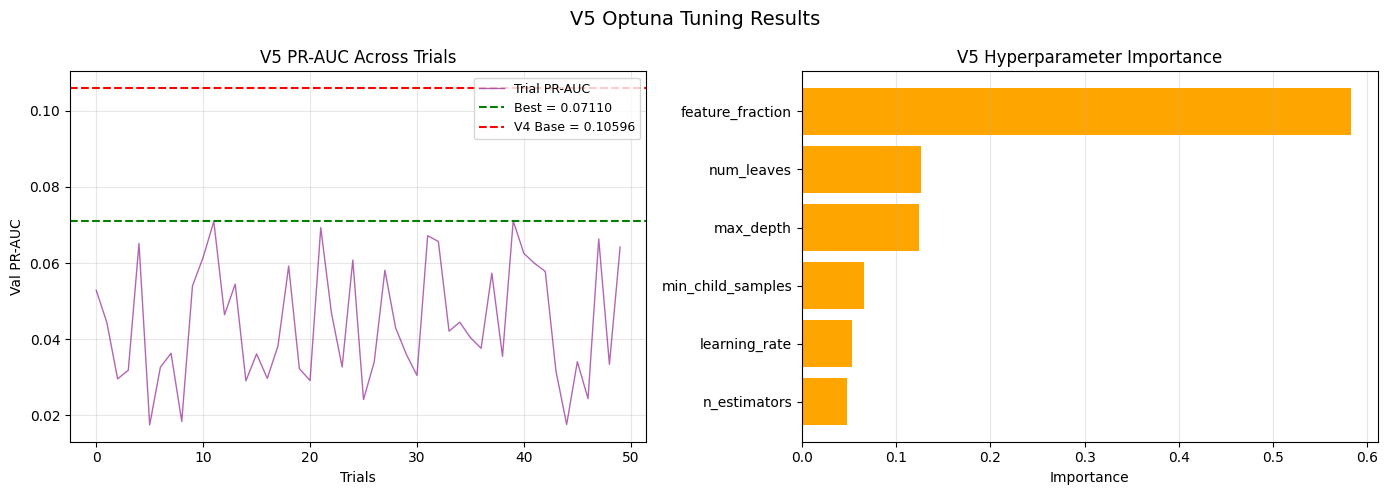

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("V5 Optuna Tuning Results", fontsize=14)

# PR-AUC Progression
ax = axes[0]
trial_values = [t.value for t in study.trials if t.value is not None]

ax.plot(trial_values, color="purple", linewidth=1, alpha=0.6, label="Trial PR-AUC")
ax.axhline(
    best_pr_auc, color="green", linestyle="--",
    linewidth=1.5, label=f"Best = {best_pr_auc:.5f}"
)
ax.axhline(
    v5_base_val_metrics["pr_auc"], color="red", linestyle="--",
    linewidth=1.5, label=f"V4 Base = {v5_base_val_metrics["pr_auc"]:.5f}"
)

ax.set_title("V5 PR-AUC Across Trials")
ax.set_xlabel("Trials")
ax.set_ylabel("Val PR-AUC")
ax.legend(fontsize=9)
ax.grid(alpha=0.3)

# Parameter Importance
ax = axes[1]
importance = optuna.importance.get_param_importances(study)
param_list = list(importance.keys())[:8]
value_list = [importance[p] for p in param_list]

ax.barh(param_list[::-1], value_list[::-1], color="orange")
ax.set_title("V5 Hyperparameter Importance")
ax.set_xlabel("Importance")
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

#### ***PR-AUC declined from 0.10596 (baseline) to 0.07110 (best Optuna trial) : Optuna made V5 LightGBM worse***

In [17]:
print("Since Optuna is worse that baseline (V2 tuned on V5), moving ahead with Baseline V5 LighGBM :-")

print(f"\nV5 scale_pos_weight : {SCALE_POS_WEIGHT}")
print(f"V5 Learning Rate : {v2_tuned_parameters['learning_rate']:.6f}")
print(f"V5 feature_fraction : {v2_tuned_parameters['feature_fraction']:.6f}")

trees_used = v2_tuned_parameters['n_estimators']
print(f"Trees Used : {trees_used}")

Since Optuna is worse that baseline (V2 tuned on V5), moving ahead with Baseline V5 LighGBM :-

V5 scale_pos_weight : 100.0001
V5 Learning Rate : 0.011270
V5 feature_fraction : 0.502818
Trees Used : 4600


### LightGBM Feature Importance

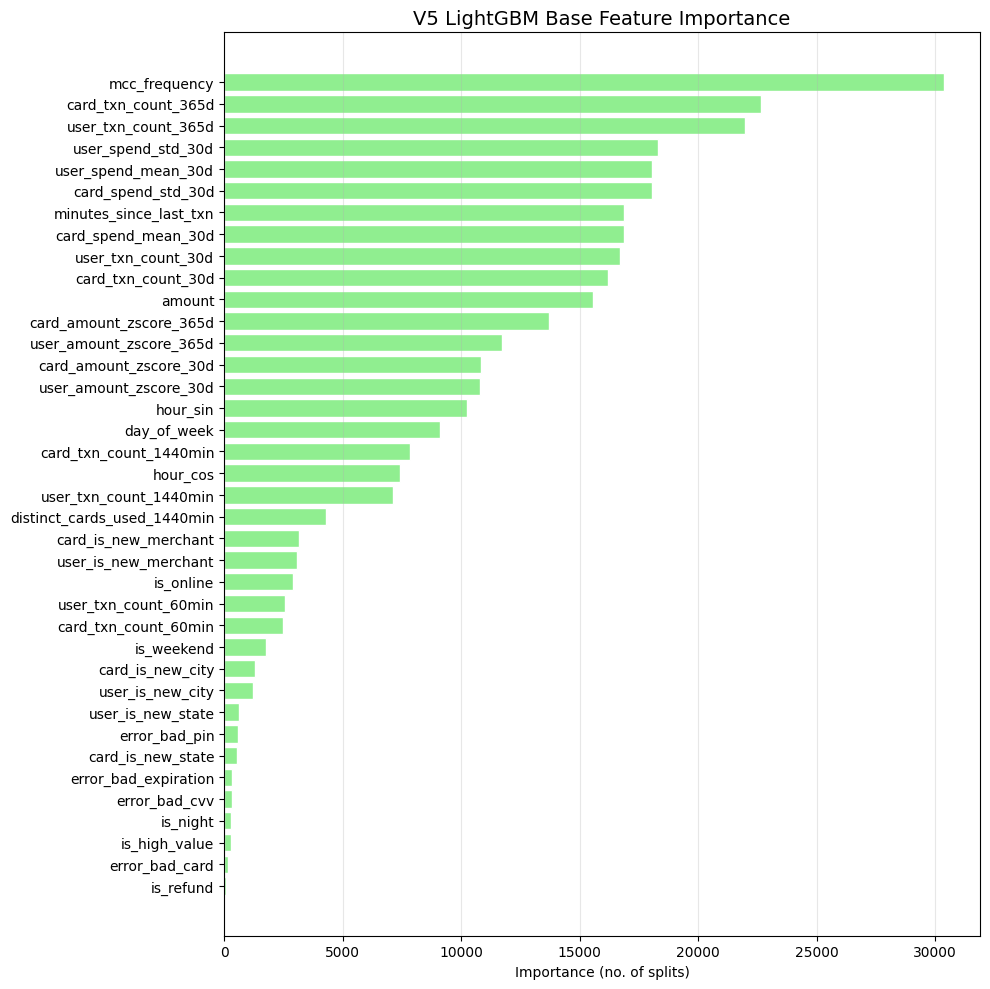


Top 10 features :
mcc_frequency                  : 30,374
card_txn_count_365d            : 22,646
user_txn_count_365d            : 21,967
user_spend_std_30d             : 18,317
user_spend_mean_30d            : 18,052
card_spend_std_30d             : 18,048
minutes_since_last_txn         : 16,893
card_spend_mean_30d            : 16,878
user_txn_count_30d             : 16,714
card_txn_count_30d             : 16,207

Zero Importance Features (0) : 


In [18]:
importance = sorted(
    zip(FEATURE_COLS, lgbm_v5_base.feature_importances_),
    key=lambda x : x[1],
    reverse=True
)
 
features = [f for f, _ in importance]
imp_values = [v for _, v in importance]

fig, ax = plt.subplots(figsize=(10, 10))

colors = ["lightgreen" if v > 0 else "red" for v in imp_values]
ax.barh(features[::-1], imp_values[::-1], color=colors[::-1], edgecolor="white")

ax.set_title("V5 LightGBM Base Feature Importance", fontsize=14)
ax.set_xlabel("Importance (no. of splits)")
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

print(f"\nTop 10 features :")
for f, v in importance[:10]:
    print(f"{f:<30} : {v:,}")

zero_imp = [f for f, v in importance if v == 0]
print(f"\nZero Importance Features ({len(zero_imp)}) : ")
for f in zero_imp:
    print(f"{f}")

In [19]:
# Clearing space
del x_val_tune, y_val_tune
gc.collect()

136

## V5 Isolation Forest

### Training & Scores

In [20]:
from sklearn.ensemble import IsolationForest

ISO_CONTAMINATION = config["model"]["isolation_forest"]["contamination"]
ISO_N_ESTIMATORS = config["model"]["isolation_forest"]["n_estimators"]

print("Training Isolation Forest on SMOTE training data (V5) ...")
print(f"Training (SMOTE) : {len(x_train_smote):,} Rows")
 
iso_forest_v5 = IsolationForest(
    contamination = ISO_CONTAMINATION,
    n_estimators = ISO_N_ESTIMATORS,
    random_state = RANDOM_STATE,
    n_jobs = -1
)

iso_forest_v5.fit(x_train_smote)
print("\nV5 Isolation Forest Trained")

# Raw Anomaly Scores on full Val
# High score- more anomalous, Low score- more normal
raw_iso_val = -iso_forest_v5.decision_function(x_val)  # Inverting

raw_iso_min = raw_iso_val.min()
raw_iso_max = raw_iso_val.max()

print("\nRaw Anomaly Score on Val :")
print(f"Mean : {raw_iso_val.mean():.5f}")
print(f"Std : {raw_iso_val.std():.5f}")
print(f"Min : {raw_iso_min:.5f}")
print(f"Max : {raw_iso_max:.5f}")

# Normalizing raw scores
norm_iso_val = (raw_iso_val - raw_iso_min) / (raw_iso_max - raw_iso_min)

print("\nNormalized Anomaly Score on Val :")
print(f"Mean : {norm_iso_val.mean():.5f}")
print(f"Std : {norm_iso_val.std():.5f}")
print(f"Min : {norm_iso_val.min():.5f}")
print(f"Max : {norm_iso_val.max():.5f}")

Training Isolation Forest on SMOTE training data (V5) ...
Training (SMOTE) : 5,177,768 Rows

V5 Isolation Forest Trained

Raw Anomaly Score on Val :
Mean : -0.15658
Std : 0.04562
Min : -0.22624
Max : 0.15420

Normalized Anomaly Score on Val :
Mean : 0.18311
Std : 0.11991
Min : 0.00000
Max : 1.00000


### Isolation Forest Fraud Signal

In [21]:
iso_fraud_mean = norm_iso_val[y_val == 1].mean()
iso_non_fraud_mean = norm_iso_val[y_val == 0].mean()
iso_pr_auc = average_precision_score(y_val, norm_iso_val)

print("V5 Isolation Forest on Val :")
print(f"Fraud Mean Anomaly Score : {iso_fraud_mean:.5f}")
print(f"Non-Fraud Mean Anomaly Score : {iso_non_fraud_mean:.5f}")
print(f"Isolation Forest PR-AUC : {iso_pr_auc:.5f}")

V5 Isolation Forest on Val :
Fraud Mean Anomaly Score : 0.32323
Non-Fraud Mean Anomaly Score : 0.18291
Isolation Forest PR-AUC : 0.00646


# V5 Hybrid Weights & Threshold

## Hybrid Weights

In [22]:
print("Calculating V5 Hybrid Weights ...")
print(f"V5 Isolation Forest PR-AUC : {iso_pr_auc:.5f}")
print(f"V5 LightGBM PR-AUC : {v5_base_val_metrics['pr_auc']:.5f}\n")

weights = []
for w1 in [0.5, 0.6, 0.7, 0.8, 0.9, 1.0]:
    w2 = round(1 - w1, 1)
    hybrid_scores = w1 * v5_base_val_prob + w2 * norm_iso_val
    pr_auc = average_precision_score(y_val, hybrid_scores)
    roc_auc = roc_auc_score(y_val, hybrid_scores)

    weights.append({
        "lgbm_weight" : w1,
        "iso_weight" : w2,
        "pr_auc" : round(pr_auc, 5),
        "roc_auc" : round(roc_auc, 5)
    })

weight_df = pd.DataFrame(weights).sort_values("pr_auc", ascending=False)
print(weight_df.to_string(index=False))

best_weights = weight_df.iloc[0]
BEST_V5_LGBM_WEIGHT = float(best_weights["lgbm_weight"])
BEST_V5_ISO_WEIGHT = float(best_weights["iso_weight"])

print("\nBest V5 Weights :-")
print(f"LightGBM V5 Weight - {BEST_V5_LGBM_WEIGHT}")
print(f"Isolation Forest V5 Weight - {BEST_V5_ISO_WEIGHT}")

print(f"\nV5 LightGBM PR-AUC : {v5_base_val_metrics['pr_auc']:.5f}")
print(f"Hybrid V5 PR-AUC : {best_weights['pr_auc']:.5f}")
print(f"Delta : {best_weights['pr_auc'] - v5_base_val_metrics['pr_auc']:+.5f}")

if BEST_V5_ISO_WEIGHT == 0.00:
    print("\nV5 Isolation Forest adds no value, V5 LightGBM alone is better than V5 hybrid")

Calculating V5 Hybrid Weights ...
V5 Isolation Forest PR-AUC : 0.00646
V5 LightGBM PR-AUC : 0.10596

 lgbm_weight  iso_weight  pr_auc  roc_auc
         1.0         0.0 0.10596  0.91449
         0.9         0.1 0.09479  0.77946
         0.8         0.2 0.08866  0.76692
         0.7         0.3 0.08319  0.76013
         0.6         0.4 0.07714  0.75537
         0.5         0.5 0.06923  0.75160

Best V5 Weights :-
LightGBM V5 Weight - 1.0
Isolation Forest V5 Weight - 0.0

V5 LightGBM PR-AUC : 0.10596
Hybrid V5 PR-AUC : 0.10596
Delta : +0.00000

V5 Isolation Forest adds no value, V5 LightGBM alone is better than V5 hybrid


### Saving to Config

In [23]:
config["model"]["v5_hybrid"]["lgbm_weight"] = BEST_V5_LGBM_WEIGHT
config["model"]["v5_hybrid"]["iso_weight"] = BEST_V5_ISO_WEIGHT

with open(CONFIG_PATH, "w") as f:
    yaml.safe_dump(config, f, sort_keys=False)

print("V5 Weights saved to config.yaml")

V5 Weights saved to config.yaml


## Probability Calibration

In [24]:
from sklearn.model_selection import train_test_split
from sklearn.isotonic import IsotonicRegression

print("Applying Isotonic probability calibration ...")
print(f"Full Val Size : {len(x_val):,}")

x_val_calib, x_val_eval, y_val_calib, y_val_eval = train_test_split(
    x_val, y_val,
    test_size = 0.5,
    random_state=RANDOM_STATE,
    stratify=y_val
)

print(f"Calibration subset : {len(x_val_calib):,} rows | {y_val_calib.sum():,} fraud")
print(f"Evaluation subset : {len(x_val_eval):,} rows | {y_val_eval.sum():,} fraud")


# Isotonic Regression

raw_calib_prob = lgbm_v5_base.predict_proba(x_val_calib)[:, 1]

iso_calib = IsotonicRegression(out_of_bounds="clip")
iso_calib.fit(raw_calib_prob, y_val_calib)
print("\nIsotonic Calibration fitted on val_calib")

calib_lgbm_v5_val_prob = iso_calib.predict(
    lgbm_v5_base.predict_proba(x_val_eval)[:, 1]
)
calib_lgbm_v5_test_prob = iso_calib.predict(
    lgbm_v5_base.predict_proba(x_test)[:, 1]
)

print("\nUncalibrated score distribution on val_eval :")
uncalib_prob = lgbm_v5_base.predict_proba(x_val_eval)[:, 1]
for pct in [90, 95, 97, 99, 99.5, 99.9]:
    print(f"\t{pct}th percentile : {np.percentile(uncalib_prob, pct):.5f}")

print("\nCalibrated score distribution on val_eval :")
for pct in [90, 95, 97, 99, 99.5, 99.9]:
    print(f"\t{pct}th percentile : {np.percentile(calib_lgbm_v5_val_prob, pct):.5f}")


improvement = np.percentile(calib_lgbm_v5_val_prob, 99) - np.percentile(uncalib_prob, 99)
print(f"\n99th percentile improvement from calibration : {improvement:+5f}")

fraud_amount_val_eval = x_val_eval.loc[y_val_eval == 1, "amount"].values

Applying Isotonic probability calibration ...
Full Val Size : 1,721,605
Calibration subset : 860,802 rows | 1,245 fraud
Evaluation subset : 860,803 rows | 1,246 fraud

Isotonic Calibration fitted on val_calib

Uncalibrated score distribution on val_eval :
	90th percentile : 0.00028
	95th percentile : 0.00094
	97th percentile : 0.00234
	99th percentile : 0.01766
	99.5th percentile : 0.05669
	99.9th percentile : 0.38652

Calibrated score distribution on val_eval :
	90th percentile : 0.00241
	95th percentile : 0.00506
	97th percentile : 0.00812
	99th percentile : 0.03245
	99.5th percentile : 0.03519
	99.9th percentile : 0.09749

99th percentile improvement from calibration : +0.014788


#### Calibration compressed the top scores rather than expanding it.
- **Uncalibrated 99.9th percentile : 0.38652**
- **Calibrated   99.9th percentile : 0.09749 (4x worse)**

#### **Root cause** : isotonic regression is fitted on 1,245 fraud cases, which is too less.
#### **Decision** : calibration discarded. Rest of the evaluations use uncalibrated probabilities from lgbm_v5_base on full val.

## Threshold Optimization

In [25]:
# Using only LightGBM Model
RECALL_FLOOR = config["model"]["recall_floor"]
FP_COST = config["model"]["fp_cost"]

fraud_prob_val = v5_base_val_prob[y_val == 1]
non_fraud_prob_val = v5_base_val_prob[y_val == 0]

v5_base_test_prob = lgbm_v5_base.predict_proba(x_test)[:, 1]

print("Optimising Threshold on V5 Val :-")
print("False Negative Cost : Actual Transaction Amount")
print(f"False Positive Cost : ${FP_COST:.2f} per False Alarms")
print(f"Recall Floor (minimun) : {RECALL_FLOOR}")

print(f"\nFruad transactions in Val : {len(fraud_amount_val):,}")
print(f"Average Fraud Amount : ${fraud_amount_val.mean():,.2f}")
print(f"Total Fraud Amount : ${fraud_amount_val.sum():,.2f}")

thresholds = np.arange(0.1, 0.99, 0.01).round(2)

# Vectorized calculation
# Shapes = (n_threshold, n_fraud_val), (n_threshold, n_non_fraud_val)
fraud_caught = fraud_prob_val[None, :] >= thresholds[:, None]
fraud_missed = ~fraud_caught

fn_loss = (fraud_missed * fraud_amount_val[None, :]).sum(axis=1)

fp_counts = (non_fraud_prob_val[None, :] >= thresholds[:, None]).sum(axis=1)
fp_loss = fp_counts * FP_COST

total_loss = fn_loss + fp_loss

threshold_result = []
for i, threshold in enumerate(thresholds):
    preds = (v5_base_val_prob >= threshold).astype(int)

    tn = int(((preds == 0) & (y_val == 0)).sum())
    fn = int(fraud_missed[i].sum())
    fp = int(fp_counts[i])
    fpr = fp / (fp + tn) if (fp + tn) > 0 else 0.00

    recall = float(recall_score(y_val, preds, zero_division=0))
    precision = float(precision_score(y_val, preds, zero_division=0))
    f1 = float(f1_score(y_val, preds, zero_division=0))

    threshold_result.append({
        "threshold" : threshold,
        "total_loss" : round(total_loss[i], 2),
        "fn_loss" : round(fn_loss[i], 2),
        "fp_loss" : round(fp_loss[i], 2),
        "fn_count" : fn,
        "fp_count" : fp,
        "recall" : round(recall, 5),
        "precision" : round(precision, 5),
        "f1" : round(f1, 5),
        "fpr" : round(fpr, 5),

    })

result_df = pd.DataFrame(threshold_result)
threshold_df = result_df[result_df["recall"] >= RECALL_FLOOR]  # balancing with fpr

if len(threshold_df) == 0:
    print(f"\nNo threshold with recall >= {RECALL_FLOOR} | Relaxing recall_floor for V5")
    
    best_row = result_df.loc[result_df["total_loss"].idxmin()]
    BEST_V5_THRESHOLD = float(best_row["threshold"])
    
    print(f"\nBest V5 Threshold (relaxed) : {BEST_V5_THRESHOLD}")
    print(f"Recall : {best_row['recall']:.5f}")
    
else:
    best_row = threshold_df.loc[threshold_df["total_loss"].idxmin()]
    BEST_V5_THRESHOLD = float(best_row["threshold"])
    
    print(f"\nBest V5 Threshold : {BEST_V5_THRESHOLD}")
    print(f"Recall : {best_row['recall']:.5f}")

print(f"\nTotal Loss : ${best_row['total_loss']:,.2f}")
print(f"FN Loss : ${best_row['fn_loss']:,.2f} ({best_row['fn_count']:,.0f} frauds missed)")
print(f"FP Loss : ${best_row['fp_loss']:,.2f} ({best_row['fp_count']:,.0f} false alarms raised)")
print(f"\nPrecision : {best_row['precision']:.5f}")
print(f"F1 : {best_row['f1']:.5f}")
print(f"PR-AUC : {average_precision_score(y_val, v5_base_val_prob):.5f}")
print(f"FPR : {best_row['fpr']:.5f}")

Optimising Threshold on V5 Val :-
False Negative Cost : Actual Transaction Amount
False Positive Cost : $2.00 per False Alarms
Recall Floor (minimun) : 0.75

Fruad transactions in Val : 2,491
Average Fraud Amount : $79.40
Total Fraud Amount : $197,795.45

No threshold with recall >= 0.75 | Relaxing recall_floor for V5

Best V5 Threshold (relaxed) : 0.1
Recall : 0.23565

Total Loss : $153,601.46
FN Loss : $143,217.46 (1,904 frauds missed)
FP Loss : $10,384.00 (5,192 false alarms raised)

Precision : 0.10157
F1 : 0.14196
PR-AUC : 0.10596
FPR : 0.00302


### Visualizing

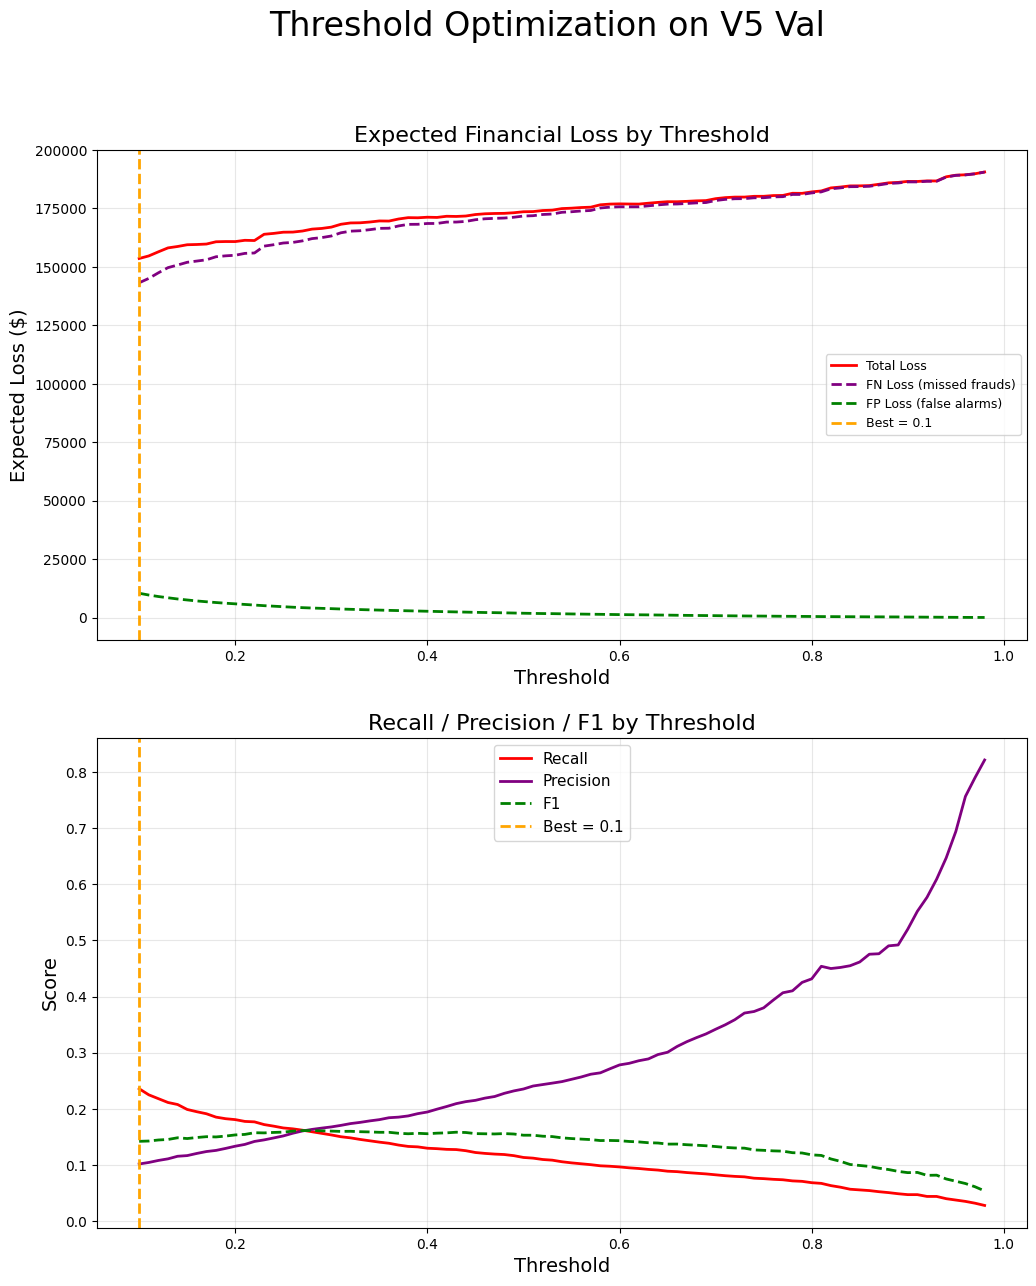

In [27]:
fig, axes = plt.subplots(2, 1, figsize=(12, 14))
fig.suptitle("Threshold Optimization on V5 Val", fontsize=24)

ax = axes[0]
ax.plot(result_df["threshold"], result_df["total_loss"], color="red",
        linewidth=2, label="Total Loss")
ax.plot(result_df["threshold"], result_df["fn_loss"], color="purple",
        linewidth=2, linestyle="--", label="FN Loss (missed frauds)")
ax.plot(result_df["threshold"], result_df["fp_loss"], color="green",
        linewidth=2, linestyle="--", label="FP Loss (false alarms)")
ax.axvline(BEST_V5_THRESHOLD, color="orange", linewidth=2, 
           linestyle="--", label=f"Best = {BEST_V5_THRESHOLD}")

ax.set_title("Expected Financial Loss by Threshold", fontsize=16)
ax.set_xlabel("Threshold", fontsize=14)
ax.set_ylabel("Expected Loss ($)", fontsize=14)
ax.legend(fontsize=9)
ax.grid(alpha=0.3)

ax = axes[1]
ax.plot(result_df["threshold"], result_df["recall"], color="red",
        linewidth=2, label="Recall")
ax.plot(result_df["threshold"], result_df["precision"], color="purple",
        linewidth=2, label="Precision")
ax.plot(result_df["threshold"], result_df["f1"], color="green",
        linewidth=2, linestyle="--", label="F1")
ax.axvline(BEST_V5_THRESHOLD, color="orange", linewidth=2, 
           linestyle="--", label=f"Best = {BEST_V5_THRESHOLD}")

ax.set_title("Recall / Precision / F1 by Threshold", fontsize=16)
ax.set_xlabel("Threshold", fontsize=14)
ax.set_ylabel("Score", fontsize=14)
ax.legend(fontsize=11)
ax.grid(alpha=0.3)

plt.show()

### Saving to Config

In [28]:
print("V5 Val score distribution :")
for pct in [90, 95, 97, 99, 99.5, 99.9]:
    val = np.percentile(v5_base_val_prob, pct)
    print(f"{pct}th percentile : {val:.5f}")

V5 Val score distribution :
90th percentile : 0.00028
95th percentile : 0.00094
97th percentile : 0.00232
99th percentile : 0.01742
99.5th percentile : 0.05618
99.9th percentile : 0.38923


In [29]:
config["model"]["v5_threshold"] = BEST_V5_THRESHOLD

config["risk"]["v5_thresholds"]["low"] = round(float(np.percentile(v5_base_val_prob, 90)), 3)
config["risk"]["v5_thresholds"]["medium"] = round(float(np.percentile(v5_base_val_prob, 95)), 3)
config["risk"]["v5_thresholds"]["high"] = round(float(np.percentile(v5_base_val_prob, 97)), 3)
config["risk"]["v5_thresholds"]["critical"] = BEST_V5_THRESHOLD

with open(CONFIG_PATH, "w") as f:
    yaml.safe_dump(config, f, sort_keys=False)

print("Saved to config.yaml")

Saved to config.yaml


# Final Evaluation on V4 Test

In [30]:
lgbm_v5_val_prob, lgbm_v5_val_metrics = evaluate_model(
    lgbm_v5_base, x_val, y_val,
    threshold=BEST_V5_THRESHOLD,
    split_name="V5 Final Val"
)

lgbm_v5_test_prob, lgbm_v5_test_metrics = evaluate_model(
    lgbm_v5_base, x_test, y_test,
    threshold=BEST_V5_THRESHOLD,
    split_name="V5 Final Test"
)

print("\n\nFinal V5 Evaluation (full Test) :")
print(f"Threshold = {BEST_V5_THRESHOLD}")

print(f"\n{'Metric':<18} {'V5 Test':>12} {'V5 Val':>12} {'Delta':>12}")
for metric in [
    "pr_auc", "roc_auc", "f1", "recall", "precision", "fpr", "recall_at_0.1_fpr",
    "recall_at_1_fpr", "precision_top_1k", "precision_top_5k", "precision_top_10k"
]:
    v5_val_metric = lgbm_v5_val_metrics.get(metric, 0.0)
    v5_test_metric = lgbm_v5_test_metrics[metric]
    delta = v5_test_metric - v5_val_metric
    print(f"{metric:<18} {v5_test_metric:>12.5f} {v5_val_metric:>12.5f} {delta:>+12.5f}")

10-10-2026 18:07:39 | INFO | V5 Final Val Evaluation (threshold = 0.1):
10-10-2026 18:07:39 | INFO | pr_auc             : 0.10596
10-10-2026 18:07:39 | INFO | roc_auc            : 0.91449
10-10-2026 18:07:39 | INFO | f1                 : 0.14196
10-10-2026 18:07:39 | INFO | recall             : 0.23565
10-10-2026 18:07:39 | INFO | precision          : 0.10157
10-10-2026 18:07:39 | INFO | fpr                : 0.00302
10-10-2026 18:07:39 | INFO | recall_at_0.1_fpr  : 0.14653
10-10-2026 18:07:39 | INFO | recall_at_1_fpr    : 0.39743
10-10-2026 18:07:39 | INFO | precision_top_1k   : 0.25600
10-10-2026 18:07:39 | INFO | precision_top_5k   : 0.10820
10-10-2026 18:07:39 | INFO | precision_top_10k  : 0.07390
10-10-2026 18:18:54 | INFO | V5 Final Test Evaluation (threshold = 0.1):
10-10-2026 18:18:54 | INFO | pr_auc             : 0.03432
10-10-2026 18:18:54 | INFO | roc_auc            : 0.90803
10-10-2026 18:18:54 | INFO | f1                 : 0.09447
10-10-2026 18:18:54 | INFO | recall        



Final V5 Evaluation (full Test) :
Threshold = 0.1

Metric                  V5 Test       V5 Val        Delta
pr_auc                  0.03432      0.10596     -0.07164
roc_auc                 0.90803      0.91449     -0.00646
f1                      0.09447      0.14196     -0.04749
recall                  0.20268      0.23565     -0.03297
precision               0.06159      0.10157     -0.03998
fpr                     0.00313      0.00302     +0.00011
recall_at_0.1_fpr       0.09583      0.14653     -0.05070
recall_at_1_fpr         0.36128      0.39743     -0.03615
precision_top_1k        0.11000      0.25600     -0.14600
precision_top_5k        0.06900      0.10820     -0.03920
precision_top_10k       0.04930      0.07390     -0.02460


#### Test metrics are significantly lower that Val metrics.
##### This is due to temporal fraud distribution and behaviour shift-
##### 1. Val (2018)  : 0.145% fraud rate -> used for threshold tuning
##### 2. Test (2019 - 2020) : 0.101% fraud rate -> 30% lower fraud & changed fraud patterns

#### There is no overfitting, but model metrics confirm score compression persists despite SMOTE.
##### ROC-AUC (0.91449 -> 0.90803) and FPR (0.00302 -> 0.00313) remain stable : model ranks fraud and non-fraud well.
##### PR-AUC (0.10596 -> 0.03432) and Precision @ Top 1K (0.25600 -> 0.11000) drop : SMOTE did not fix post-chip compression

## Financial Impact

In [31]:
test_fraud_prob = lgbm_v5_test_prob[y_test == 1]
test_non_fraud_prob = lgbm_v5_test_prob[y_test == 0]

test_fraud_caught = int((test_fraud_prob >= BEST_V5_THRESHOLD).sum())
test_fraud_missed = int((test_fraud_prob < BEST_V5_THRESHOLD).sum())
test_false_alarms = int((test_non_fraud_prob >= BEST_V5_THRESHOLD).sum())

test_fn_loss = float(test_fraud_amount[test_fraud_prob < BEST_V5_THRESHOLD].sum())
test_fp_loss = test_false_alarms * FP_COST
test_total_loss = test_fn_loss + test_fp_loss

print("Financial Impact on V5 Test data :")
print(f"Fraud Caught : {test_fraud_caught:,} / {len(test_fraud_amount):,} ({test_fraud_caught / len(test_fraud_amount) * 100:.2f}%)")
print(f"Fraud Missed : {test_fraud_missed:,}")
print(f"False Alarms : {test_false_alarms:,}")

print(f"\nFN Loss : ${test_fn_loss:,.2f}")
print(f"FP Loss : ${test_fp_loss:,.2f}")
print(f"Total Loss : ${test_total_loss:,.2f}")

Financial Impact on V5 Test data :
Fraud Caught : 423 / 2,087 (20.27%)
Fraud Missed : 1,664
False Alarms : 6,445

FN Loss : $129,382.43
FP Loss : $12,890.00
Total Loss : $142,272.43


## Visualization

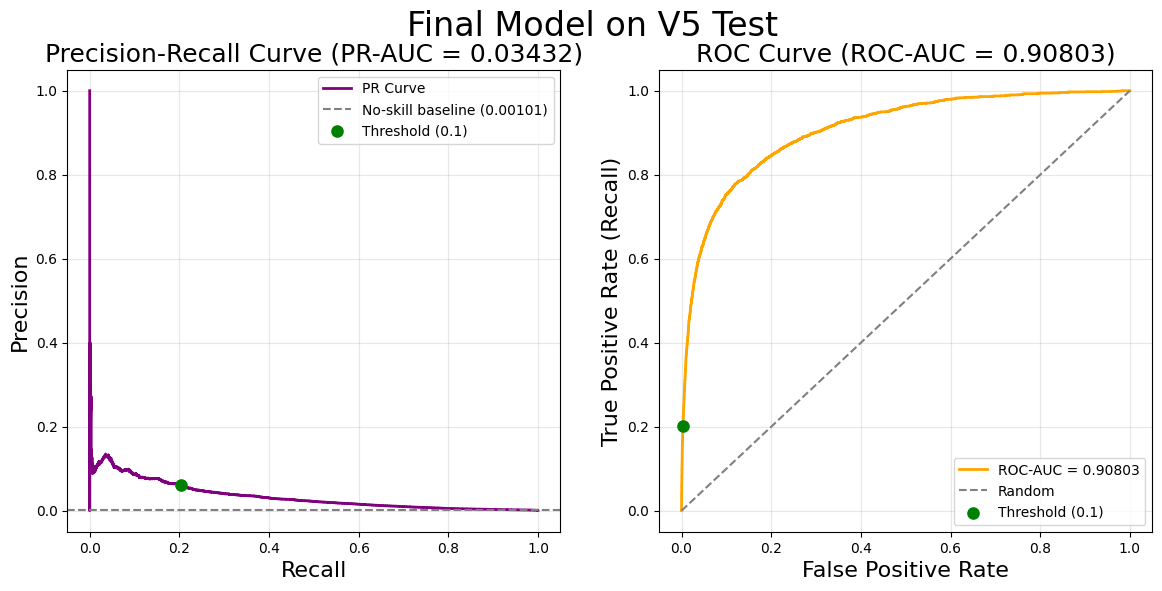

In [32]:
from sklearn.metrics import precision_recall_curve

pr_arr, rec_arr, _ = precision_recall_curve(y_test, lgbm_v5_test_prob)
fpr_arr, tpr_arr, _ = roc_curve(y_test, lgbm_v5_test_prob)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle("Final Model on V5 Test", fontsize=24)

ax = axes[0]
ax.plot(rec_arr, pr_arr, color="purple", linewidth=2, label="PR Curve")
ax.axhline(y_test.mean(), color="gray", linestyle="--", 
        label=f"No-skill baseline ({y_test.mean():.5f})")
ax.scatter(lgbm_v5_test_metrics["recall"], lgbm_v5_test_metrics["precision"],
           color="green", s=65, zorder=5, label=f"Threshold ({BEST_V5_THRESHOLD})")

ax.set_title(
    f"Precision-Recall Curve (PR-AUC = {lgbm_v5_test_metrics['pr_auc']:.5f})",
    fontsize=18
)
ax.set_xlabel("Recall", fontsize=16)
ax.set_ylabel("Precision", fontsize=16)
ax.legend(fontsize=10)
ax.grid(alpha=0.3)

ax = axes[1]
ax.plot(fpr_arr, tpr_arr, color="orange", linewidth=2, 
        label=f"ROC-AUC = {lgbm_v5_test_metrics["roc_auc"]:.5f}")
ax.plot([0, 1], [0, 1], color="gray", linestyle="--", label="Random")
ax.scatter(lgbm_v5_test_metrics['fpr'], lgbm_v5_test_metrics['recall'], 
            color="green", s=65, zorder=5, label=f"Threshold ({BEST_V5_THRESHOLD})")

ax.set_title(
    f"ROC Curve (ROC-AUC = {lgbm_v5_test_metrics['roc_auc']:.5f})",
    fontsize=18
)
ax.set_xlabel("False Positive Rate", fontsize=16)
ax.set_ylabel("True Positive Rate (Recall)", fontsize=16)
ax.legend(fontsize=10)
ax.grid(alpha=0.3)

plt.show()

#### Out of 10,000 alerts-
##### Random Classification : 10 actual frauds, 9990 false alarms (0.00101)
##### Model Classification : 616 actual frauds, 9384 false alarms (0.06159)

#### Model is 61x better at identifying frauds.

## Saving Artifacts

In [33]:
lgbm_path = PROJECT_ROOT / config["artifacts"]["lgbm_v5_path"]
iso_path = PROJECT_ROOT / config["artifacts"]["iso_v5_path"]

joblib.dump(lgbm_v5_base, lgbm_path)
joblib.dump(iso_forest_v5, iso_path)

print("Saved as model artifacts")

Saved as model artifacts


# Summary

In [35]:
print("V5 Data :")
print(f"Train ({V5_TRAIN_START} to {V5_TRAIN_END}) : {len(x_train_smote):,} Rows (after SMOTE)")
print(f"Val ({V5_VAL_START} to {V5_VAL_END}) : {len(x_val):,} Rows")
print(f"Test ({V5_TEST_START} to {V5_TEST_END}) : {len(x_test):,} Rows")
print(f"Features : {len(FEATURE_COLS)}")

print("\nV5 Model :")
print("Algorithm : LightGBM")
print(f"Trees Used : {trees_used}")
print(f"scale_pos_weight : {SCALE_POS_WEIGHT}")
print(f"Hybrid weight : {config["model"]["v5_hybrid"]["lgbm_weight"]}\n")
for key, value in config["model"]["lgbm"]["v2_tuned"].items():
    print(f"{key:<18} : {value}")

print("\nIsolation Forest :")
print(f"Hybrid weight : {config["model"]["v5_hybrid"]["iso_weight"]}")
print("Most optimal V5 model is LightGBM only")

print(f"\nThreshold : {BEST_V5_THRESHOLD}")
print(f"FP Cost : ${FP_COST:.2f}")
print("FN Cost : actual transaction amount")

delta = lgbm_v5_val_metrics['recall'] - RECALL_FLOOR
print(f"\nRecall Floor : {RECALL_FLOOR}")
print(f"Recall achieved : {lgbm_v5_val_metrics['recall']:.6f} | delta : {delta:+.6f}")
if delta < 0.0:
    print(f"Recall floor not achievable, threshold optimized to minimize expected financial loss")

print(f"\nV5 retrained as a candidate model for promotion")

print(f"\nVal Metrics (threshold={BEST_V5_THRESHOLD})")
for key, value in lgbm_v5_val_metrics.items():
    print(f"{key:<18} : {value:.5f}")

print(f"\nTest Metrics (threshold={BEST_V5_THRESHOLD})")
for key, value in lgbm_v5_test_metrics.items():
    print(f"{key:<18} : {value:.5f}")

print("\nFinancial Impact on V5 Test :")
print(f"Fraud Caught : {test_fraud_caught:,} / {len(test_fraud_amount):,} ({test_fraud_caught / len(test_fraud_amount) * 100:.2f}%)")
print(f"False Alarms : {test_false_alarms:,}")
print(f"FN Loss : ${test_fn_loss:,.2f}")
print(f"FP Loss : ${test_fp_loss:,.2f}")
print(f"Total Loss : ${test_total_loss:,.2f}")

print("\nArtifacts :")
print(f"{lgbm_path.name}")
print(f"{iso_path.name}")

V5 Data :
Train (2015 to 2017) : 5,177,768 Rows (after SMOTE)
Val (2018 to 2018) : 1,721,605 Rows
Test (2019 to 2020) : 2,060,423 Rows
Features : 38

V5 Model :
Algorithm : LightGBM
Trees Used : 4600
scale_pos_weight : 100.0001
Hybrid weight : 1.0

learning_rate      : 0.011269656488047454
max_depth          : 12
n_estimators       : 4600
num_leaves         : 72
feature_fraction   : 0.5028180600816718
min_child_samples  : 119
reg_alpha          : 0
reg_lambda         : 1e-06

Isolation Forest :
Hybrid weight : 0.0
Most optimal V5 model is LightGBM only

Threshold : 0.1
FP Cost : $2.00
FN Cost : actual transaction amount

Recall Floor : 0.75
Recall achieved : 0.235650 | delta : -0.514350
Recall floor not achievable, threshold optimized to minimize expected financial loss

V5 retrained as a candidate model for promotion

Val Metrics (threshold=0.1)
pr_auc             : 0.10596
roc_auc            : 0.91449
f1                 : 0.14196
recall             : 0.23565
precision          : 0.10

## Post-Chip Retraining Conclusion (V2 - V5)

#### All four post-chip retraining attempts failed to meet the recall floor of 0.75.
##### V2 LightGBM (full era 1991-2017) : recall 0.394, PR-AUC 0.053 : pre-chip data dilutes post-chip signal
##### V3 CatBoost (full era 1991-2017) : recall 0.726, PR-AUC 0.066 : FPR 5.3% - operationally unacceptable
##### V4 LightGBM (post-chip 2015-2017) : recall 0.242, PR-AUC 0.034 : insufficient fraud signal (7,115 examples)
##### V5 LightGBM (post-chip + SMOTE) : recall 0.203, PR-AUC 0.034 : SMOTE did not fix score compression

#### Root cause : 7,115 post-chip fraud examples are insufficient for confident fraud scoring regardless of algorithm or resampling strategy.

#### Decision : V1 remains the active deployed model. V3 CatBoost saved as best post-chip candidate.